# PII 마스킹

이 절은 질문에 든 개인정보(PII, personally identifiable information)를 가립니다.
가리기를 영어로 마스킹(masking)이라고 부릅니다.

**이 노트북에서 할 일**

1. 가짜 개인정보 넷이 든 질문을 만들고 01절 입력 검사에 겁니다.
2. 정규 표현식 넷으로 이메일·전화번호·주민등록번호·카드 번호를 찾아 표식으로 바꿉니다.
3. 가리지 않고 쓰는 흐름이 메시지와 기록 한 줄에 원문을 남기는 것을 봅니다(Before).
4. 가린 뒤에 보내고 남기면 두 곳 모두 원문이 남지 않는 것을 봅니다(After).

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 한 번이고 임베딩 요청은 없습니다.
노트북을 한 번 실행하는 요금은 요금표로 어림해 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 `data/retrieved-documents.json` 하나입니다.
새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 3초 만에 끝났습니다.

질문에 넣은 개인정보 넷은 모두 이 절에서 지어낸 가짜 값입니다.
실제 사람의 정보는 쓰지 않습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 4~6절을 읽습니다.
정규식으로 값을 찾아 가리고, 가리지 않은 흐름이 무엇을 남기는지 보는 자리입니다.
7절은 가린 뒤에 보내고 남기는 자리입니다.
8절 손 확인과 9절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch16-guardrails`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

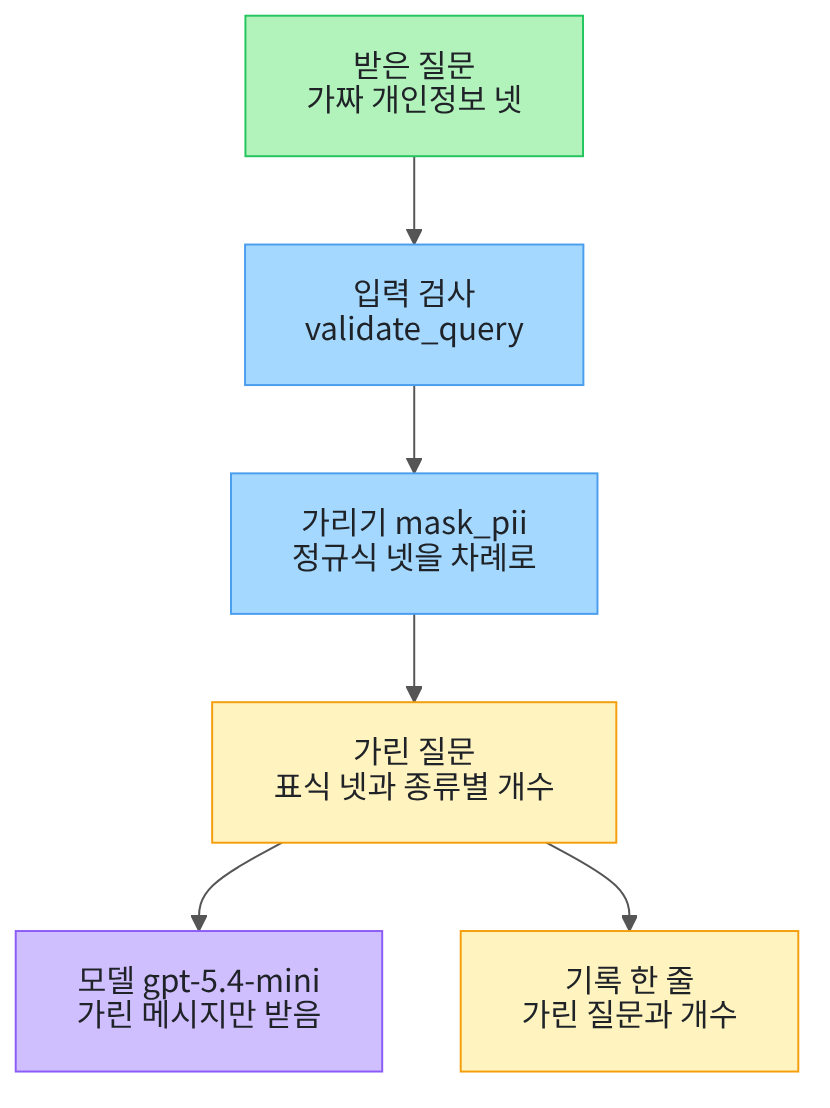

위에서 아래로 읽습니다. 초록 질문이 파란 입력 검사와 파란 가리기를 차례로 지납니다.
노란 가린 질문에서 화살표가 둘로 나뉘어 보라 모델과 노란 기록 한 줄로 갑니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 다섯을 불러옵니다.
모듈 `re`는 파이썬에 들어 있는 정규 표현식 기능입니다.
이 과정에서 `re`를 쓰는 것은 이 절이 처음입니다.

앞에서 배운 함수는 `guardrails.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
이 절은 그 파일에서 01절 입력 검사 함수 `validate_query` 하나만 가져옵니다.

In [2]:
# 파일을 읽을 이름, 정규 표현식 모듈, 01절 입력 검사 함수, 모델을 만들 이름을 불러옵니다
import json
import os
import re

from guardrails import validate_query
from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "os", "re", "validate_query", "init_chat_model")

불러온 이름: json os re validate_query init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json os re validate_query init_chat_model`로 이름 다섯을 불러왔습니다.
함수 `validate_query`는 01절 노트북에서 정의한 함수와 같은 본문입니다.

## 2. 키와 모델 준비

이 절은 7절에서 가린 질문을 답 모델 `gpt-5.4-mini`에 한 번 보냅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 답 문장이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 자료와 이 절에서 정한 값

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch16-guardrails/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 01절과 같은 자료 파일을 읽고 안내 문서 `E01` 하나를 고릅니다.
이 절의 검색 결과는 이 문서 하나입니다.

In [6]:
# 자료 파일을 읽고 이 절의 검색 결과로 안내 문서 E01 하나만 고릅니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch16-guardrails/data"
with open(data_path + "/retrieved-documents.json", encoding="utf-8") as file:
    all_documents = json.loads(file.read())
retrieved = []
for document in all_documents:
    if document["doc_id"] == "E01":
        retrieved.append(document)
print("자료 파일의 문서 수:", len(all_documents))
print("이번 검색 결과의 문서 수:", len(retrieved))

자료 파일의 문서 수: 2
이번 검색 결과의 문서 수: 1


**결과 읽기** — 출력 줄 `자료 파일의 문서 수: 2`로 자료 파일의 문서는 둘입니다.
출력 줄 `이번 검색 결과의 문서 수: 1`로 이 절은 안내 문서 하나만 씁니다.

다음 셀은 이 절에서 정한 값을 적습니다.
글자 수 상한과 시스템 메시지 글은 01절과 같습니다.
검색 문서 한 줄도 01절과 같은 모양으로 만듭니다.

In [7]:
# 이 절에서 정한 값입니다: 01절과 같은 글자 수 상한·지킬 말과 검색 문서 한 줄입니다
max_chars = 500
system_text = "검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요."
document = retrieved[0]
document_line = "검색 문서 " + document["doc_id"] + " " + str(document["page"]) + "쪽: " + document["text"]
print("정한 질문 글자 수 상한:", max_chars)
print("검색 문서 한 줄:")
print(document_line)

정한 질문 글자 수 상한: 500
검색 문서 한 줄:
검색 문서 E01 1쪽: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.


**결과 읽기** — 출력 줄 `정한 질문 글자 수 상한: 500`이 01절과 같은 상한입니다.
라벨 줄 `검색 문서 한 줄:` 아래 줄이 모델에게 함께 보낼 문서입니다.
이 문서에는 개인정보가 없습니다.
코드 첫 줄 주석의 「지킬 말」은 01절과 같은 시스템 메시지 글을 가리킵니다.

다음 셀은 이 절에서 지어낸 가짜 개인정보 넷을 적습니다.
실제 사람의 정보가 아니고, 가짜임이 드러나게 정한 값입니다.

In [8]:
# 이 절에서 지어낸 가짜 개인정보 넷입니다(실제 사람의 정보가 아닙니다)
fake_email = "test.user@example.com"
fake_phone = "010-0000-0000"
fake_rrn = "123456-1234567"
fake_card = "1111-2222-3333-4444"
fake_values = [fake_email, fake_phone, fake_rrn, fake_card]
print("가짜 값 수:", len(fake_values))
print("가짜 값:", fake_values)

가짜 값 수: 4
가짜 값: ['test.user@example.com', '010-0000-0000', '123456-1234567', '1111-2222-3333-4444']


**결과 읽기** — 출력 줄 `가짜 값 수: 4`로 값은 넷입니다.
차례로 이메일, 휴대 전화번호, 주민등록번호, 카드 번호입니다.

이메일의 `example.com`은 문서 예시용으로 따로 떼어 둔 주소 이름입니다.
전화번호는 가운데와 끝자리가 모두 0입니다.
주민등록번호 앞자리 `123456`은 34월 56일이라 있을 수 없는 날짜입니다.
카드 번호는 같은 숫자를 네 자리씩 늘어놓아 모양만 맞췄습니다.

다음 셀은 글 안에 이 값이 원문 그대로 남았는지 찾는 함수입니다.

In [9]:
# 글 안에 원문 그대로 남은 가짜 값만 모읍니다
def find_raw_values(text, values):
    remaining = []
    for value in values:
        if value in text:
            remaining.append(value)
    return remaining

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `find_raw_values`는 글 하나와 값 목록을 받습니다.
값마다 조건 `value in text`로 글 안에 그 값이 그대로 들어 있는지 봅니다.
들어 있는 값만 새 목록에 담아 내놓습니다.

다음 셀은 가짜 값 넷을 넣은 질문을 만들고 01절 입력 검사에 겁니다.
휴관일을 묻고, 답을 받을 연락처와 주민등록번호·카드 번호를 함께 적은 질문입니다.

In [10]:
# 가짜 값 넷을 넣은 질문을 만들고 01절 입력 검사에 겁니다
contact_line = "답은 " + fake_email + " 이나 " + fake_phone + " 으로 보내 주세요."
member_line = "주민등록번호는 " + fake_rrn + " 이고, 연체료는 카드 " + fake_card + " 로 내겠습니다."
question = "도서관 휴관일은 언제인가요? " + contact_line + " " + member_line
checked_question = validate_query(question, max_chars)
raw_in_question = find_raw_values(checked_question, fake_values)
print("입력 검사를 지난 질문:")
print(checked_question)
print("질문에 든 원문 값 수:", len(raw_in_question))

입력 검사를 지난 질문:
도서관 휴관일은 언제인가요? 답은 test.user@example.com 이나 010-0000-0000 으로 보내 주세요. 주민등록번호는 123456-1234567 이고, 연체료는 카드 1111-2222-3333-4444 로 내겠습니다.
질문에 든 원문 값 수: 4


**결과 읽기** — 라벨 줄 `입력 검사를 지난 질문:` 아래 줄이 이 절의 질문입니다.
출력 줄 `질문에 든 원문 값 수: 4`로 가짜 값 넷이 모두 들어 있습니다.
01절 입력 검사는 빈칸과 글자 수만 보므로 이 질문을 막지 않았습니다.

휴관일을 답하는 데에는 이 넷이 하나도 필요하지 않습니다.
다음 소절부터 이 값을 찾아 가리는 방법을 배웁니다.

## 4. 정규 표현식으로 찾기

정규 표현식(regular expression)은 글자 모양을 적은 짧은 규칙입니다.
이 교재에서는 줄여서 정규식이라고도 부릅니다.
값을 하나하나 적는 대신 「숫자 셋, 붙임표, 숫자 넷」처럼 모양을 적어 찾습니다.
이 절 코드에서는 `r"…"` 꼴 글 하나가 정규식 하나입니다.

함수 `re.findall(정규식, 글)`은 글에서 정규식에 맞는 부분을 모두 찾아 목록으로 내놓습니다.
글 앞의 `r`은 역슬래시(`\`)를 글자 그대로 두라는 표시입니다.
정규식에는 역슬래시가 자주 들어가서 이 표시를 붙입니다.

첫 정규식은 이메일 모양입니다. 기호는 하나씩 봅니다.

- 대괄호 `[ ]`는 그 안에 적은 글자 가운데 한 글자에 맞습니다.
- 기호 `\w`는 글자·숫자·밑줄 가운데 한 글자이고, 한글 글자도 여기에 들어갑니다.
- 그래서 `[\w.]`는 그런 글자나 점 한 글자입니다. 대괄호 안의 점은 점 그대로입니다.
- 기호 `+`는 바로 앞 규칙이 한 번 이상 이어진다는 뜻입니다.
- 가운데 `@`는 골뱅이 글자 그대로입니다.

In [11]:
# 이메일 모양 정규식으로 질문에서 이메일을 찾습니다
email_pattern = r"[\w.]+@[\w.]+"
print("이메일 정규식:", email_pattern)
print("찾은 이메일:", re.findall(email_pattern, checked_question))

이메일 정규식: [\w.]+@[\w.]+
찾은 이메일: ['test.user@example.com']


**결과 읽기** — 출력 줄 `찾은 이메일: ['test.user@example.com']`으로 질문에서 이메일 하나를 찾았습니다.
점이 섞인 글자 덩어리, 골뱅이, 다시 점이 섞인 글자 덩어리가 이어진 부분입니다.

둘째 정규식은 휴대 전화번호 모양입니다.

- 맨 앞 `01`은 글자 0과 1 그대로입니다.
- 대괄호 `[016789]`는 0·1·6·7·8·9 가운데 한 글자입니다.
- 기호 `?`는 바로 앞 글자가 없어도 되고 한 번 있어도 된다는 뜻입니다. 그래서 `-?`는 붙임표가 있어도 없어도 맞습니다.
- 기호 `\d`는 숫자 한 글자입니다.
- 중괄호 `{3,4}`는 바로 앞 규칙이 세 번이나 네 번 이어진다는 뜻입니다. 중괄호 `{4}`는 꼭 네 번입니다.

In [12]:
# 휴대 전화번호 모양 정규식으로 질문에서 전화번호를 찾습니다
phone_pattern = r"01[016789]-?\d{3,4}-?\d{4}"
print("전화번호 정규식:", phone_pattern)
print("찾은 전화번호:", re.findall(phone_pattern, checked_question))

전화번호 정규식: 01[016789]-?\d{3,4}-?\d{4}
찾은 전화번호: ['010-0000-0000']


**결과 읽기** — 출력 줄 `찾은 전화번호: ['010-0000-0000']`으로 전화번호 하나를 찾았습니다.
앞 세 글자 `010`이 `01[016789]`에 맞고, 붙임표 둘이 `-?` 자리에 맞았습니다.
가운데 `0000`과 끝 `0000`이 숫자 자리에 맞았습니다.

셋째 정규식은 주민등록번호 모양입니다.
앞 여섯 자리, 붙임표 자리, 뒤 일곱 자리 차례입니다.

- 대괄호 안의 `1-4`는 1부터 4까지 숫자 가운데 한 글자라는 뜻입니다.
- 뒷자리 첫 글자를 이 넷으로 좁혔습니다. 나머지 `\d{6}`과 `-?`는 앞에서 본 기호입니다.

In [13]:
# 주민등록번호 모양 정규식으로 질문에서 주민등록번호를 찾습니다
rrn_pattern = r"\d{6}-?[1-4]\d{6}"
print("주민등록번호 정규식:", rrn_pattern)
print("찾은 주민등록번호:", re.findall(rrn_pattern, checked_question))

주민등록번호 정규식: \d{6}-?[1-4]\d{6}
찾은 주민등록번호: ['123456-1234567']


**결과 읽기** — 출력 줄 `찾은 주민등록번호: ['123456-1234567']`로 값 하나를 찾았습니다.
뒷자리 첫 글자 1이 `[1-4]` 자리에 맞았습니다.

넷째 정규식은 카드 번호 모양입니다.
숫자 네 자리를 붙임표로 이어 네 번 적은 모양입니다.
새 기호는 없습니다.
이 정규식의 붙임표에는 `?`가 없어서 붙임표가 꼭 있어야 맞습니다.

In [14]:
# 카드 번호 모양 정규식으로 질문에서 카드 번호를 찾습니다
card_pattern = r"\d{4}-\d{4}-\d{4}-\d{4}"
print("카드 번호 정규식:", card_pattern)
print("찾은 카드 번호:", re.findall(card_pattern, checked_question))

카드 번호 정규식: \d{4}-\d{4}-\d{4}-\d{4}
찾은 카드 번호: ['1111-2222-3333-4444']


**결과 읽기** — 출력 줄 `찾은 카드 번호: ['1111-2222-3333-4444']`로 값 하나를 찾았습니다.
정규식 넷이 질문에서 값을 하나씩 찾았습니다.

## 5. 표식으로 바꾸기

찾은 값은 표식으로 바꿉니다.
표식은 가린 자리에 종류 이름만 남긴 짧은 글입니다.
쪽지에 천을 덮고 천 위에 무엇을 덮었는지 표시하는 것과 같습니다.
이 절의 표식은 `<EMAIL_MASKED>`처럼 꺾쇠 안에 종류 이름을 적습니다.

함수 `re.sub(정규식, 바꿀 글, 글)`은 맞는 부분을 모두 바꾼 새 글을 내놓습니다.
먼저 이메일 하나만 바꿔 봅니다.

In [15]:
# 질문의 이메일을 표식 <EMAIL_MASKED>로 바꿉니다
email_masked = re.sub(email_pattern, "<EMAIL_MASKED>", checked_question)
print("이메일만 바꾼 질문:")
print(email_masked)

이메일만 바꾼 질문:
도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 010-0000-0000 으로 보내 주세요. 주민등록번호는 123456-1234567 이고, 연체료는 카드 1111-2222-3333-4444 로 내겠습니다.


**결과 읽기** — 라벨 줄 `이메일만 바꾼 질문:` 아래 줄에서 이메일 자리가 `<EMAIL_MASKED>`로 바뀌었습니다.
전화번호·주민등록번호·카드 번호는 아직 원문 그대로입니다.
원래 질문 `checked_question`은 그대로 두고 바꾼 글은 `email_masked`에 담았습니다.

이제 정규식 넷을 한 번에 겁니다.
정규식과 종류 이름을 같은 차례로 목록 둘에 담습니다.
이름을 모두 대문자로 적은 것은 한 번 정하면 바꾸지 않는 값이라는 표시입니다.

In [16]:
# 정규식 넷과 종류 이름 넷을 같은 차례로 목록 둘에 담습니다
PII_PATTERNS = [email_pattern, phone_pattern, rrn_pattern, card_pattern]
PII_NAMES = ["email", "phone", "rrn", "card"]
print("정규식 수:", len(PII_PATTERNS))
print("종류 이름:", PII_NAMES)

정규식 수: 4
종류 이름: ['email', 'phone', 'rrn', 'card']


**결과 읽기** — 출력 줄 `정규식 수: 4`와 `종류 이름: ['email', 'phone', 'rrn', 'card']`가 두 목록입니다.
두 목록은 같은 번호 자리끼리 한 짝입니다.
0번 자리는 이메일 정규식과 이름 `email`이고, 3번 자리는 카드 번호 정규식과 이름 `card`입니다.

다음 셀은 가리기 함수 `mask_pii`입니다.
번호 `i`로 두 목록을 함께 돌며 정규식을 하나씩 겁니다.
정규식마다 `re.findall`로 맞는 값의 개수를 먼저 세고, 그다음 `re.sub`로 바꿉니다.
앞 정규식이 바꾼 글에 다음 정규식을 겁니다.

표식은 종류 이름을 대문자로 바꿔 `<`와 `_MASKED>` 사이에 넣어 만듭니다.
글 메서드 `upper()`는 영문 소문자를 대문자로 바꾼 새 글을 내놓습니다.
마지막 줄 `return masked, counts`는 가린 글과 개수 딕셔너리를 함께 내놓습니다.
쉼표로 이은 두 값은 튜플 하나로 묶여 나갑니다.

In [17]:
# 개인정보 네 가지를 표식으로 바꾸고 종류별 개수를 셉니다
def mask_pii(text):
    masked = text
    counts = {}
    for i in range(len(PII_NAMES)):
        mark = "<" + PII_NAMES[i].upper() + "_MASKED>"
        found = re.findall(PII_PATTERNS[i], masked)
        counts[PII_NAMES[i]] = len(found)
        masked = re.sub(PII_PATTERNS[i], mark, masked)
    return masked, counts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `mask_pii`는 글 하나를 받아 가린 글과 종류별 개수를 함께 내놓습니다.
개수 딕셔너리의 키는 종류 이름 넷입니다.

다음 셀은 입력 검사를 지난 질문을 이 함수로 가립니다.
왼쪽에 이름 둘을 쉼표로 적으면 함수가 내놓은 튜플의 두 값을 차례로 받습니다.
가린 글은 `masked_question`에, 개수 딕셔너리는 `pii_counts`에 담깁니다.

In [18]:
# 입력 검사를 지난 질문을 가리고 종류별 개수와 남은 원문 값을 봅니다
masked_question, pii_counts = mask_pii(checked_question)
raw_in_masked = find_raw_values(masked_question, fake_values)
print("가린 질문:")
print(masked_question)
print("종류별 개수:", pii_counts)
print("가린 질문에 남은 원문 값 수:", len(raw_in_masked))

가린 질문:
도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 <PHONE_MASKED> 으로 보내 주세요. 주민등록번호는 <RRN_MASKED> 이고, 연체료는 카드 <CARD_MASKED> 로 내겠습니다.
종류별 개수: {'email': 1, 'phone': 1, 'rrn': 1, 'card': 1}
가린 질문에 남은 원문 값 수: 0


**결과 읽기** — 라벨 줄 `가린 질문:` 아래 줄에서 값 넷이 모두 표식으로 바뀌었습니다.
출력 줄 `종류별 개수: {'email': 1, 'phone': 1, 'rrn': 1, 'card': 1}`로 종류마다 하나씩 찾았습니다.
출력 줄 `가린 질문에 남은 원문 값 수: 0`으로 원문은 하나도 남지 않았습니다.

휴관일을 묻는 앞 문장은 그대로입니다.
표식 자리를 보면 어떤 종류의 값이 있었는지는 알 수 있습니다.

## 6. 가리지 않고 쓰는 흐름 (Before)

Before 셀은 가리기 함수를 만들어 두고도 부르지 않은 흐름입니다.
입력 검사를 지난 질문 `checked_question`을 그대로 메시지와 기록 한 줄에 담습니다.
이 흐름은 보내기 직전에서 멈추고 실제로 모델에 보내지는 않았습니다.

먼저 모델에게 보낼 메시지를 만듭니다.
메시지 모양은 01절과 같은 역할 딕셔너리 두 개입니다.

In [19]:
# 가리지 않는 흐름입니다: 입력 검사를 지난 질문을 그대로 메시지에 담습니다(보내지는 않습니다)
raw_messages = [
    {"role": "system", "content": system_text},
    {"role": "user", "content": "질문: " + checked_question + "\n" + document_line},
]
raw_sent = find_raw_values(raw_messages[1]["content"], fake_values)
print("보낼 사용자 메시지:")
print(raw_messages[1]["content"])
print("보낼 사용자 메시지에 남은 원문 값 수:", len(raw_sent))

보낼 사용자 메시지:
질문: 도서관 휴관일은 언제인가요? 답은 test.user@example.com 이나 010-0000-0000 으로 보내 주세요. 주민등록번호는 123456-1234567 이고, 연체료는 카드 1111-2222-3333-4444 로 내겠습니다.
검색 문서 E01 1쪽: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.
보낼 사용자 메시지에 남은 원문 값 수: 4


**결과 읽기** — 라벨 줄 `보낼 사용자 메시지:` 아래 두 줄이 모델에게 갈 글입니다.
첫 줄 질문에 가짜 값 넷이 원문 그대로 있습니다.
출력 줄 `보낼 사용자 메시지에 남은 원문 값 수: 4`가 이 흐름의 결함입니다.
이대로 보내면 모델 서비스가 개인정보 넷을 그대로 받습니다.

다음 셀은 같은 질문을 기록 한 줄로 바꿉니다.
Ch 15 08절처럼 `json.dumps(…, ensure_ascii=False)`로 딕셔너리를 JSON 글 한 줄로 바꿉니다.
이 절은 기록을 파일에 쓰지 않고 글로만 만듭니다.

In [20]:
# 가리지 않는 흐름입니다: 같은 질문을 그대로 기록 한 줄로 바꿉니다
raw_row = {"event": "question", "question": checked_question}
raw_log_line = json.dumps(raw_row, ensure_ascii=False)
raw_logged = find_raw_values(raw_log_line, fake_values)
print("기록 한 줄:")
print(raw_log_line)
print("기록 한 줄에 남은 원문 값 수:", len(raw_logged))

기록 한 줄:
{"event": "question", "question": "도서관 휴관일은 언제인가요? 답은 test.user@example.com 이나 010-0000-0000 으로 보내 주세요. 주민등록번호는 123456-1234567 이고, 연체료는 카드 1111-2222-3333-4444 로 내겠습니다."}
기록 한 줄에 남은 원문 값 수: 4


**결과 읽기** — 라벨 줄 `기록 한 줄:` 아래 줄에 가짜 값 넷이 원문 그대로 들어 있습니다.
출력 줄 `기록 한 줄에 남은 원문 값 수: 4`도 이 흐름의 결함입니다.
이 줄이 기록 파일에 들어가면 원문 넷이 그대로 남습니다.

가리기 함수는 5절에서 이미 만들었습니다.
함수를 만들어 두어도 보내는 코드와 남기는 코드가 부르지 않으면 원문이 나갑니다.

## 7. 가린 뒤에 보내고 남기는 흐름 (After)

After 셀은 5절에서 가린 질문 `masked_question`을 씁니다.
메시지와 기록 한 줄에 원문 대신 표식이 들어갑니다.
먼저 모델에게 보낼 메시지를 만듭니다.

In [21]:
# 가린 질문으로 메시지를 만들고 원문 값이 남았는지 봅니다
masked_messages = [
    {"role": "system", "content": system_text},
    {"role": "user", "content": "질문: " + masked_question + "\n" + document_line},
]
masked_sent = find_raw_values(masked_messages[1]["content"], fake_values)
print("보낼 사용자 메시지:")
print(masked_messages[1]["content"])
print("보낼 사용자 메시지에 남은 원문 값 수:", len(masked_sent))

보낼 사용자 메시지:
질문: 도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 <PHONE_MASKED> 으로 보내 주세요. 주민등록번호는 <RRN_MASKED> 이고, 연체료는 카드 <CARD_MASKED> 로 내겠습니다.
검색 문서 E01 1쪽: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.
보낼 사용자 메시지에 남은 원문 값 수: 0


**결과 읽기** — 라벨 줄 `보낼 사용자 메시지:` 아래 첫 줄에 표식 넷이 보입니다.
출력 줄 `보낼 사용자 메시지에 남은 원문 값 수: 0`으로 원문은 남지 않았습니다.

앞 6절 Before 셀에서는 `보낼 사용자 메시지에 남은 원문 값 수: 4`였습니다.

다음 셀은 가린 메시지만 모델에게 보냅니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [22]:
# 가린 메시지만 모델에게 보냅니다(모델 요청 1번)
model_answer = model.invoke(masked_messages).text
answer_raw = find_raw_values(model_answer, fake_values)
print("모델이 쓴 답:")
print(model_answer)
print("답에 든 원문 값 수:", len(answer_raw))

모델이 쓴 답:
미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 p.1]
답에 든 원문 값 수: 0


**결과 읽기** — 라벨 줄 `모델이 쓴 답:` 아래 줄이 모델 답입니다.
출력 줄 `답에 든 원문 값 수: 0`으로 답에도 원문 값이 없습니다.
모델이 받은 글에 원문이 없었기 때문입니다.

이 답은 모델이 쓴 글이라 여러분 실행에서는 문장이 다를 수 있습니다.
교재 출력을 만들기 전에 같은 요청을 따로 다섯 번 보냈습니다.
다섯 번 모두 같은 답이었고 끝에 출처 표시 `[E01 p.1]`이 붙었습니다.

다음 셀은 가린 질문과 종류별 개수만 기록 한 줄로 바꿉니다.
개수는 어떤 종류를 가렸는지 뒤에서 알아볼 때 씁니다.

In [23]:
# 가린 질문과 종류별 개수만 기록 한 줄로 바꿉니다
safe_row = {"event": "question", "question": masked_question, "pii": pii_counts}
safe_log_line = json.dumps(safe_row, ensure_ascii=False)
safe_logged = find_raw_values(safe_log_line, fake_values)
print("기록 한 줄:")
print(safe_log_line)
print("기록 한 줄에 남은 원문 값 수:", len(safe_logged))

기록 한 줄:
{"event": "question", "question": "도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 <PHONE_MASKED> 으로 보내 주세요. 주민등록번호는 <RRN_MASKED> 이고, 연체료는 카드 <CARD_MASKED> 로 내겠습니다.", "pii": {"email": 1, "phone": 1, "rrn": 1, "card": 1}}
기록 한 줄에 남은 원문 값 수: 0


**결과 읽기** — 라벨 줄 `기록 한 줄:` 아래 줄에 표식 넷과 종류별 개수가 들어 있습니다.
출력 줄 `기록 한 줄에 남은 원문 값 수: 0`으로 기록에도 원문이 남지 않았습니다.

앞 6절 Before 셀에서는 `기록 한 줄에 남은 원문 값 수: 4`였습니다.

다음 셀은 두 흐름의 원문 값 수를 한 표로 나란히 봅니다.

In [24]:
# 두 흐름에서 원문 값이 남은 수를 한 표로 나란히 봅니다
print("흐름 | 보낼 사용자 메시지 | 기록 한 줄")
print("가리지 않은 흐름 |", len(raw_sent), "|", len(raw_logged))
print("가린 흐름 |", len(masked_sent), "|", len(safe_logged))

흐름 | 보낼 사용자 메시지 | 기록 한 줄
가리지 않은 흐름 | 4 | 4
가린 흐름 | 0 | 0


**결과 읽기** — 라벨 줄 `흐름 | 보낼 사용자 메시지 | 기록 한 줄` 아래 두 줄이 두 흐름입니다.
출력 줄 `가리지 않은 흐름 | 4 | 4`로 가리지 않은 흐름은 두 곳 모두 원문 넷을 담았습니다.
출력 줄 `가린 흐름 | 0 | 0`으로 가린 흐름은 두 곳 모두 원문이 없습니다.
두 흐름은 같은 질문을 썼고 가리기를 불렀는지만 달랐습니다.

## 8. 손으로 적은 글로 확인하기

다음 셀은 손으로 적은 글 둘로 가리기를 확인합니다.
첫째 글에는 01절의 출처 표시 `[E01 p.1]`을 함께 적었습니다.
가리기가 출력 검사에 쓸 표시를 건드리면 안 되기 때문입니다.

둘째 글은 이메일 바로 뒤에 조사 「으로」를 붙여 썼습니다.
함수 결과 뒤의 `[0]`은 튜플의 첫째 값인 가린 글만 꺼냅니다.
미리 정한 글이라 결과를 `assert`로 확인할 수 있습니다.

In [25]:
# 손으로 적은 글 둘로 가리기를 확인합니다(미리 정한 글이라 assert로 봅니다)
source_sample = "메일 test.user@example.com, 출처 [E01 p.1]"
particle_sample = "메일 test.user@example.com으로 주세요"
source_masked, source_counts = mask_pii(source_sample)
particle_masked = mask_pii(particle_sample)[0]
print("출처 표시가 든 글:", source_masked)
print("조사를 붙여 쓴 글:", particle_masked)
assert source_masked == "메일 <EMAIL_MASKED>, 출처 [E01 p.1]"
assert source_counts == {"email": 1, "phone": 0, "rrn": 0, "card": 0}

출처 표시가 든 글: 메일 <EMAIL_MASKED>, 출처 [E01 p.1]
조사를 붙여 쓴 글: 메일 <EMAIL_MASKED> 주세요


**결과 읽기** — 출력 줄 `출처 표시가 든 글: 메일 <EMAIL_MASKED>, 출처 [E01 p.1]`에서 출처 표시가 그대로 남았습니다.
마지막 두 줄의 `assert`도 통과했습니다.

출력 줄 `조사를 붙여 쓴 글: 메일 <EMAIL_MASKED> 주세요`에서는 조사 「으로」까지 사라졌습니다.
기호 `\w`가 한글 글자도 한 글자로 보아 조사까지 이메일로 묶었기 때문입니다.
그래서 이 절의 질문은 이메일 뒤에 빈칸을 두었습니다.

## 9. 값 바꿔 보기 · 빈칸으로 적은 전화번호

바꿀 값은 질문 속 전화번호의 모양 하나입니다.
붙임표 대신 빈칸으로 적은 번호 `010 0000 0000`으로 바꾸고 같은 함수로 가립니다.
글 메서드 `replace(찾을 글, 바꿀 글)`는 찾은 글을 바꾼 새 글을 내놓습니다.

실행 전에 예상해 봅니다.
전화번호 정규식의 `-?` 자리는 붙임표만 받으므로 이 번호는 찾지 못할 것입니다.
나머지 셋은 5절처럼 하나씩 찾을 것입니다.

In [26]:
# 바꿀 값은 전화번호 모양 하나입니다: 질문의 번호를 빈칸으로 적은 모양으로 바꿔 가립니다
spaced_phone = "010 0000 0000"
spaced_question = checked_question.replace(fake_phone, spaced_phone)
spaced_masked, spaced_counts = mask_pii(spaced_question)
spaced_raw = find_raw_values(spaced_masked, [spaced_phone])
print("가린 질문:")
print(spaced_masked)
print("종류별 개수:", spaced_counts)
print("남은 원문 값 수:", len(spaced_raw))

가린 질문:
도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 010 0000 0000 으로 보내 주세요. 주민등록번호는 <RRN_MASKED> 이고, 연체료는 카드 <CARD_MASKED> 로 내겠습니다.
종류별 개수: {'email': 1, 'phone': 0, 'rrn': 1, 'card': 1}
남은 원문 값 수: 1


**결과 읽기** — 라벨 줄 `가린 질문:` 아래 줄에 `010 0000 0000`이 원문 그대로 남았습니다.
출력 줄 `종류별 개수: {'email': 1, 'phone': 0, 'rrn': 1, 'card': 1}`로 전화번호만 0개입니다.
출력 줄 `남은 원문 값 수: 1`이 놓친 번호 하나입니다.

예상대로 정규식은 적어 둔 모양만 찾았습니다.
5절 출력에서는 `'phone': 1`이었습니다.
실제 입력에 어떤 모양이 들어오는지 먼저 보고 정규식을 정해야 합니다.

## 정리

1. 정규식 넷으로 이메일·전화번호·주민등록번호·카드 번호를 찾아 표식으로 바꿨습니다.
2. 가리지 않은 흐름은 보낼 메시지와 기록 한 줄에 원문 값 넷을 그대로 담았습니다.
3. 가린 흐름은 두 곳 모두 원문 값이 없었고, 빈칸으로 적은 전화번호는 찾지 못했습니다.

03절에서는 길어진 대화 기록을 자르는 방법과 요약하는 방법을 견줍니다.